# Part 2 — training strategy, augmentation, and distillation

Use one experiment runner for all configurations. **A0 and A1** compare linear and cosine decay with the same single linear classifier. **A2** adds augmentation and label smoothing to A1 while preserving that classifier, so its comparison changes only the training inputs and targets. The optional MLP-head comparison remains separate under distinct run IDs.

All students start from scratch on the same Imagenette training subset. The A0/A1/A2 and MLP controls use no teacher. **C0 (soft)** and **C1 (hard)** use a two-token, two-head student and the same frozen CNN teacher checkpoint. These custom 100-epoch runs do not reproduce the full published DeiT recipe. The historical Part 1 plateau-scheduler results are not the new A0 result. Execute each training cell manually when ready; each starts a full training run. The notebook has not been executed for full training.


In [1]:
import hashlib
import json
import random
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

from datasets.augmentation import build_image_transform, build_batch_transform
from datasets.imagenette import download_imagenette_dataset
from models.vision_transformer import (
    build_distilled_vision_transformer,
    build_vision_transformer,
    build_vision_transformer_single_classifier,
)
from pipeline.evaluate import evaluate_model
from pipeline.train import train_model

SEED = 0
SPLIT_SEED = 0
EPOCHS = 100
WARMUP_EPOCHS = 5
BATCH_SIZE = 32
PEAK_LR = 5e-4
WEIGHT_DECAY = 0.01
LABEL_SMOOTHING = 0.1  # A2/C0/C1 dataset targets; clean controls stay unsmoothed.
DATA_ROOT = Path("data")
RESULTS_DIR = Path("artifacts/part2/") / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
MODEL_CONFIG = dict(image_size=224, patch_size=16, hidden_dim=192, num_heads=4,
                    num_layers=6, mlp_ratio=4, num_classes=10, dropout=0.1)
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def save_json(path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, default=lambda value: value.tolist()) + "\n")

print(f"Device: {device}; results: {RESULTS_DIR}")

Device: mps; results: artifacts/part2/20261112_205445_UTC


## One fixed split and clean validation

Use only Imagenette's official **training** split, reserving a stratified 20% for internal validation. The official validation/test split is not loaded. A0, A1, and the MLP comparison use deterministic resize, center crop, and tensors in [0,1]. A2 uses a separate dataset instance with the same original training indices. Validation always uses the original clean instance.

Save the indices, image order, and class mapping once for every run in this session.

In [2]:
pool = download_imagenette_dataset(root_dir=str(DATA_ROOT), split="train", image_size=224)
labels = np.array([label for _, label in pool._samples])
train_indices, validation_indices = train_test_split(
    np.arange(len(pool)), test_size=0.2, stratify=labels, random_state=SPLIT_SEED,
)
train_data = Subset(pool, train_indices.tolist())
validation_data = Subset(pool, validation_indices.tolist())
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
np.savez(RESULTS_DIR / "split_indices.npz", train=train_indices, validation=validation_indices)
save_json(RESULTS_DIR / "dataset_manifest.json", {
    "dataset": "Imagenette", "distribution": "320px", "official_split": "train",
    "split_seed": SPLIT_SEED, "class_to_idx": pool.class_to_idx,
    "ordered_samples": [
        {"image": str(Path(path).relative_to(Path(pool._image_root))), "label": int(label)}
        for path, label in pool._samples
    ],
})
print(f"Training: {len(train_data)}; internal validation: {len(validation_data)}")

Training: 7575; internal validation: 1894


## One shared runner

Every call rebuilds the model and resets the initialization, dropout, sampling, and augmentation seeds. Each loader has a fresh generator with the same seed. This provides a matched starting point; stochastic augmentation can consume different random draws, and seeds do not guarantee bitwise reproducibility on every backend.

Keep 100 epochs, batch size 32, AdamW, actual peak LR 0.0005, weight decay 0.01, dropout 0.1, five warmup epochs, warmup LR `1e-6`, and minimum LR `1e-5`. There is no implicit batch-size scaling. Disable early stopping and retain the existing **highest validation accuracy** checkpoint rule in every run.

A0/A1 isolate the decay shape. A1/A2 isolate the augmentation-and-smoothing package. Image transforms run when the dataset loads an example; an optional batch transform runs once on the collated batch before the model. Validation keeps ordinary, unmixed ground-truth labels. Training loss with mixed, smoothed targets is not directly comparable to clean validation loss and need not approach zero.
Every training criterion has the same interface: `criterion(images, outputs, targets)`. The supervised criterion ignores images and trains the available head(s) against the dataset targets. Distillation trains CLS against those same mixed/smoothed targets and DIST against the frozen teacher's prediction for the identical input batch. The two-head evaluator averages the heads' softmax probabilities, then measures clean-label NLL and accuracy; the teacher is absent from inference. Each run records its loss settings and, for distillation, the teacher identity and dataset-metadata check status.


In [3]:
from pipeline.losses import supervised_loss

histories, summaries = {}, {}

def run_experiment(run_id, model_builder, *, scheduler, train_dataset,
                   criterion=supervised_loss, batch_transform=None, teacher_info=None):
    reset_seed(SEED)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED), drop_last=False,
    )
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    model = model_builder(**MODEL_CONFIG)
    source_dataset = train_dataset.dataset if isinstance(train_dataset, Subset) else train_dataset
    two_heads = hasattr(model, "cls_head") and hasattr(model, "dist_head")
    loss_config = dict(getattr(criterion, "config", {"mode": "supervised"}))
    target_description = ("class distributions from the batch transform" if batch_transform is not None
                          else "ground-truth class indices")
    if loss_config["mode"] == "supervised":
        supervision = "cross-entropy against " + target_description + "; equal weights across available heads"
    else:
        if teacher_info is None:
            raise ValueError("Distillation requires the loaded teacher's identity and data-verification status.")
        supervision = "CLS: " + target_description + "; DIST: " + loss_config["mode"] + " teacher targets"
    run_dir = RESULTS_DIR / run_id
    checkpoint = run_dir / "best.pth"
    config = dict(
        run_id=run_id, model=MODEL_CONFIG, model_builder=model_builder.__name__,
        classifier_head=repr(model.cls_head if two_heads else model.mlp_head),
        distillation_head=repr(model.dist_head) if two_heads else None,
        student_seed=SEED, split_seed=SPLIT_SEED,
        epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, scheduler=scheduler, warmup_steps=warmup_steps,
        warmup_lr=1e-6, min_lr=1e-5, early_stopping_patience=None,
        supervision=supervision, loss=loss_config, teacher=teacher_info,
        evaluation=("average two head probabilities; clean labels" if two_heads
                    else "single-head prediction; clean labels"),
        evaluation_diagnostics=True, checkpoint_rule="highest validation accuracy",
        image_transform=repr(source_dataset.transform), batch_transform=repr(batch_transform),
        device=str(device), torch_version=torch.__version__,
        split_indices="../split_indices.npz", dataset_manifest="../dataset_manifest.json",
    )
    save_json(run_dir / "config.json", config)
    history = train_model(
        model, train_loader, validation_loader, num_epochs=EPOCHS, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, device=device, checkpoint_path=checkpoint, criterion=criterion,
        scheduler=scheduler, warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
        early_stopping_patience=None, batch_transform=batch_transform,
    )
    metrics = evaluate_model(model, validation_loader, device, checkpoint_path=checkpoint, diagnostics=True)
    summary = dict(run_id=run_id, parameters=sum(p.numel() for p in model.parameters()),
                   epochs_run=len(history["train_loss"]), best_epoch=history["best_epoch"],
                   validation=metrics, training_seconds=sum(history["train_seconds"]),
                   checkpoint=str(checkpoint))
    save_json(run_dir / "history.json", history)
    save_json(run_dir / "summary.json", summary)
    histories[run_id], summaries[run_id] = history, summary
    model.cpu()
    print(f"{run_id}: validation accuracy={metrics['accuracy']:.4f}, "
          f"loss={metrics['loss']:.4f}, macro F1={metrics['macro_f1_score']:.4f}")
    return history, summary


## A0 — single linear classifier, linear decay

A0 establishes the controlled reference. It uses one CLS token and one linear classifier, with no augmentation or teacher.

In [4]:
a0_history, a0_summary = run_experiment(
    "A0_linear", build_vision_transformer_single_classifier,
    scheduler="linear", train_dataset=train_data,
)

Epoch 1/100: train loss=2.2185, val loss=2.0725, val accuracy=0.2445, lr_start=1e-06, train=20.01s, val=3.17s
Epoch 2/100: train loss=1.9437, val loss=1.7777, val accuracy=0.3833, lr_start=0.0001, train=19.77s, val=3.12s
Epoch 3/100: train loss=1.7268, val loss=1.6674, val accuracy=0.4388, lr_start=0.0002, train=19.66s, val=3.12s
Epoch 4/100: train loss=1.5832, val loss=1.5207, val accuracy=0.4979, lr_start=0.0003, train=19.85s, val=3.15s
Epoch 5/100: train loss=1.5082, val loss=1.4916, val accuracy=0.4937, lr_start=0.0004, train=19.51s, val=3.20s
Epoch 6/100: train loss=1.3940, val loss=1.5515, val accuracy=0.4683, lr_start=0.0005, train=19.47s, val=3.12s
Epoch 7/100: train loss=1.3207, val loss=1.4050, val accuracy=0.5306, lr_start=0.00049, train=19.44s, val=3.18s
Epoch 8/100: train loss=1.2322, val loss=1.3674, val accuracy=0.5391, lr_start=0.00049, train=19.57s, val=3.23s
Epoch 9/100: train loss=1.1427, val loss=1.3593, val accuracy=0.5565, lr_start=0.00048, train=19.72s, val=3.20s

## A1 — single linear classifier, cosine decay

A1 uses the same model, initial seed, clean data, and warmup as A0. Only the post-warmup decay shape changes; it does not continue A0's checkpoint.

In [5]:
a1_history, a1_summary = run_experiment(
    "A1_cosine", build_vision_transformer_single_classifier,
    scheduler="cosine_decay", train_dataset=train_data,
)

Epoch 1/100: train loss=2.2185, val loss=2.0725, val accuracy=0.2445, lr_start=1e-06, train=19.26s, val=2.62s
Epoch 2/100: train loss=1.9437, val loss=1.7777, val accuracy=0.3833, lr_start=0.0001, train=18.38s, val=2.60s
Epoch 3/100: train loss=1.7268, val loss=1.6674, val accuracy=0.4388, lr_start=0.0002, train=17.39s, val=2.58s
Epoch 4/100: train loss=1.5832, val loss=1.5207, val accuracy=0.4979, lr_start=0.0003, train=17.39s, val=2.62s
Epoch 5/100: train loss=1.5082, val loss=1.4916, val accuracy=0.4937, lr_start=0.0004, train=18.42s, val=3.13s
Epoch 6/100: train loss=1.3950, val loss=1.5542, val accuracy=0.4694, lr_start=0.0005, train=19.38s, val=3.19s
Epoch 7/100: train loss=1.3264, val loss=1.4273, val accuracy=0.5232, lr_start=0.0005, train=19.13s, val=3.15s
Epoch 8/100: train loss=1.2482, val loss=1.3393, val accuracy=0.5576, lr_start=0.0005, train=18.82s, val=3.18s
Epoch 9/100: train loss=1.1483, val loss=1.3186, val accuracy=0.5665, lr_start=0.0005, train=19.70s, val=3.17s
Ep

## Optional separate MLP-head comparison

These cells preserve your comparison with the two-layer GELU classification head. They keep clean training inputs and use unique IDs, so their checkpoints and histories cannot overwrite A0/A1. Compare MLP_A0 with MLP_A1 for scheduling within the MLP model, and each with the corresponding linear-head run for the effect of the head. They are not the reference for A2.

In [6]:
mlp_a0_history, mlp_a0_summary = run_experiment(
    "MLP_A0_linear", build_vision_transformer,
    scheduler="linear", train_dataset=train_data,
)

Epoch 1/100: train loss=2.1786, val loss=2.1102, val accuracy=0.2254, lr_start=1e-06, train=18.79s, val=2.79s
Epoch 2/100: train loss=1.9764, val loss=1.8966, val accuracy=0.3432, lr_start=0.0001, train=19.17s, val=3.23s
Epoch 3/100: train loss=1.7824, val loss=1.6945, val accuracy=0.4319, lr_start=0.0002, train=18.41s, val=2.63s
Epoch 4/100: train loss=1.6529, val loss=1.5683, val accuracy=0.4646, lr_start=0.0003, train=17.29s, val=2.65s
Epoch 5/100: train loss=1.5406, val loss=1.5376, val accuracy=0.4694, lr_start=0.0004, train=18.46s, val=3.14s
Epoch 6/100: train loss=1.4095, val loss=1.4219, val accuracy=0.5143, lr_start=0.0005, train=18.84s, val=3.18s
Epoch 7/100: train loss=1.3438, val loss=1.3905, val accuracy=0.5333, lr_start=0.00049, train=19.04s, val=3.16s
Epoch 8/100: train loss=1.2697, val loss=1.4521, val accuracy=0.5100, lr_start=0.00049, train=18.69s, val=3.22s
Epoch 9/100: train loss=1.1807, val loss=1.3267, val accuracy=0.5459, lr_start=0.00048, train=18.62s, val=3.21s

In [7]:
mlp_a1_history, mlp_a1_summary = run_experiment(
    "MLP_A1_cosine", build_vision_transformer,
    scheduler="cosine_decay", train_dataset=train_data,
)

Epoch 1/100: train loss=2.1786, val loss=2.1102, val accuracy=0.2254, lr_start=1e-06, train=17.46s, val=2.61s
Epoch 2/100: train loss=1.9764, val loss=1.8966, val accuracy=0.3432, lr_start=0.0001, train=17.43s, val=2.62s
Epoch 3/100: train loss=1.7824, val loss=1.6945, val accuracy=0.4319, lr_start=0.0002, train=17.41s, val=2.61s
Epoch 4/100: train loss=1.6529, val loss=1.5683, val accuracy=0.4646, lr_start=0.0003, train=17.43s, val=2.63s
Epoch 5/100: train loss=1.5406, val loss=1.5376, val accuracy=0.4694, lr_start=0.0004, train=17.45s, val=2.63s
Epoch 6/100: train loss=1.4072, val loss=1.4835, val accuracy=0.5000, lr_start=0.0005, train=17.40s, val=2.60s
Epoch 7/100: train loss=1.3497, val loss=1.3969, val accuracy=0.5248, lr_start=0.0005, train=17.40s, val=2.60s
Epoch 8/100: train loss=1.2593, val loss=1.4959, val accuracy=0.5074, lr_start=0.0005, train=17.43s, val=2.61s
Epoch 9/100: train loss=1.2004, val loss=1.2899, val accuracy=0.5644, lr_start=0.0005, train=17.40s, val=2.60s
Ep

## Compare completed runs

Plot only the runs executed in this kernel. Report clean validation results at each selected checkpoint, selected epochs, and actual training time. Single-seed differences remain exploratory; A2 changes a package of augmentations and label smoothing, so it cannot assign an individual contribution to each ingredient. Configurations record the actual head and both transform stages. No held-out test score is produced.

The same evaluator now also records 10-bin top-label ECE (confidence versus accuracy; lower is better), unscaled multiclass Brier score (squared probability error summed across classes; range 0–2, lower is better), and mean confidence and true-label NLL separately for correct and incorrect predictions. ECE is bin-dependent. Conditional confidence and NLL describe each model's own error subset; neither is a standalone model-ranking score. Empty groups are reported as `None`/JSON `null`. All confidence values and ECE use 0–1 units.


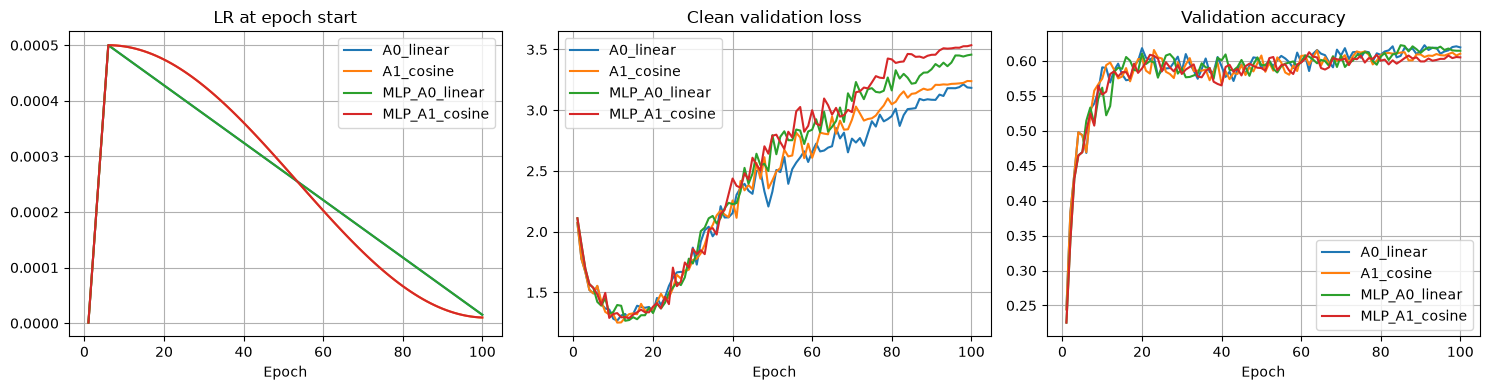

A0_linear selected epoch: 91 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6179896230864282, 'loss': 3.08482443971644, 'brier_score': 0.6828541312543809, 'ece': 0.3180005153544727, 'mean_confidence_incorrect': 0.8950377702713013}
A1_cosine selected epoch: 23 {'accuracy': 0.6156282998944034, 'macro_f1_score': 0.612395428063586, 'loss': 1.4334607119293374, 'brier_score': 0.5740851850564251, 'ece': 0.16159408488394467, 'mean_confidence_incorrect': 0.6749886870384216}
MLP_A0_linear selected epoch: 85 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6193434172041952, 'loss': 3.218034697938494, 'brier_score': 0.6707321918417717, 'ece': 0.3113274028428379, 'mean_confidence_incorrect': 0.8839903473854065}
MLP_A1_cosine selected epoch: 62 {'accuracy': 0.6124604012671595, 'macro_f1_score': 0.6081444226277524, 'loss': 2.872995398238443, 'brier_score': 0.6645175331721924, 'ece': 0.2967610700644057, 'mean_confidence_incorrect': 0.8410415053367615}


In [8]:
def compare_completed_runs():
    if histories:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for run_id, history in histories.items():
            epochs = np.arange(1, len(history["train_loss"]) + 1)
            axes[0].plot(epochs, history["learning_rate"], label=run_id)
            axes[1].plot(epochs, history["val_loss"], label=run_id)
            axes[2].plot(epochs, history["val_accuracy"], label=run_id)
        for axis, title in zip(axes, ["LR at epoch start", "Clean validation loss", "Validation accuracy"]):
            axis.set(title=title, xlabel="Epoch")
            axis.grid(True)
            axis.legend()
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / "training_comparison.png", dpi=160)
        plt.show()
        comparison_metrics = ("accuracy", "macro_f1_score", "loss", "brier_score", "ece",
                              "mean_confidence_incorrect")
        for run_id, summary in summaries.items():
            print(run_id, "selected epoch:", summary["best_epoch"],
                  {name: summary["validation"][name] for name in comparison_metrics})
    else:
        print("No runs have been executed in this kernel.")

compare_completed_runs()


## A2 — add augmentation and label smoothing to A1

The image helper performs crop, horizontal flip, and torchvision RandAugment on the PIL image, then converts it to a tensor before random erasing. The batch helper chooses **MixUp or CutMix** for each training batch; these operations receive batched images and labels rather than individual PIL images.

Keep A1's **single linear classifier** here. Switching to the MLP builder at the same time would change both the head and augmentation. Use a separate augmented pool without replacing the clean pool or resplitting. After MixUp or CutMix, smooth the dataset targets once with epsilon 0.1: q = 0.9 * q + 0.1 / num_classes. Ordinary cross-entropy then uses those targets without additional smoothing. For ten classes, an unmixed one-hot target becomes 0.91 for its class and 0.01 for every other class. Validation and test targets remain original class indices, with unsmoothed NLL. No normalization is added, preserving the present input convention; torchvision's RandAugment and erasing remain adaptations, not the exact historical timm recipe.

Use a distinct run ID for this revised A2; previous unsmoothed A2 checkpoints do not acquire the effect of smoothing through evaluation. Their training must be repeated to measure this revised configuration.

In [9]:
image_transform = build_image_transform(MODEL_CONFIG["image_size"])
batch_transform = build_batch_transform(MODEL_CONFIG["num_classes"], label_smoothing=LABEL_SMOOTHING)
augmented_pool = download_imagenette_dataset(
    root_dir=str(DATA_ROOT), split="train", image_size=224, transform=image_transform,
)
assert augmented_pool._samples == pool._samples, "Image order or class targets changed."
assert augmented_pool.class_to_idx == pool.class_to_idx, "Class mapping changed."
augmented_train_data = Subset(augmented_pool, train_indices.tolist())
a2_history, a2_summary = run_experiment(
    "A2_augmentation_smoothing", build_vision_transformer_single_classifier,
    scheduler="cosine_decay", train_dataset=augmented_train_data, batch_transform=batch_transform,
)

Epoch 1/100: train loss=2.3222, val loss=2.2089, val accuracy=0.1758, lr_start=1e-06, train=22.27s, val=2.65s
Epoch 2/100: train loss=2.2795, val loss=2.1928, val accuracy=0.1827, lr_start=0.0001, train=20.10s, val=2.65s
Epoch 3/100: train loss=2.2475, val loss=2.1642, val accuracy=0.2144, lr_start=0.0002, train=21.74s, val=2.71s
Epoch 4/100: train loss=2.2036, val loss=1.9825, val accuracy=0.3442, lr_start=0.0003, train=20.16s, val=2.64s
Epoch 5/100: train loss=2.1784, val loss=1.9420, val accuracy=0.2973, lr_start=0.0004, train=21.61s, val=3.10s
Epoch 6/100: train loss=2.1467, val loss=1.8894, val accuracy=0.3279, lr_start=0.0005, train=20.77s, val=2.67s
Epoch 7/100: train loss=2.1216, val loss=1.7964, val accuracy=0.3960, lr_start=0.0005, train=20.18s, val=2.66s
Epoch 8/100: train loss=2.1148, val loss=1.7866, val accuracy=0.4034, lr_start=0.0005, train=20.23s, val=2.68s
Epoch 9/100: train loss=2.0885, val loss=1.6639, val accuracy=0.4678, lr_start=0.0005, train=20.22s, val=2.65s
Ep

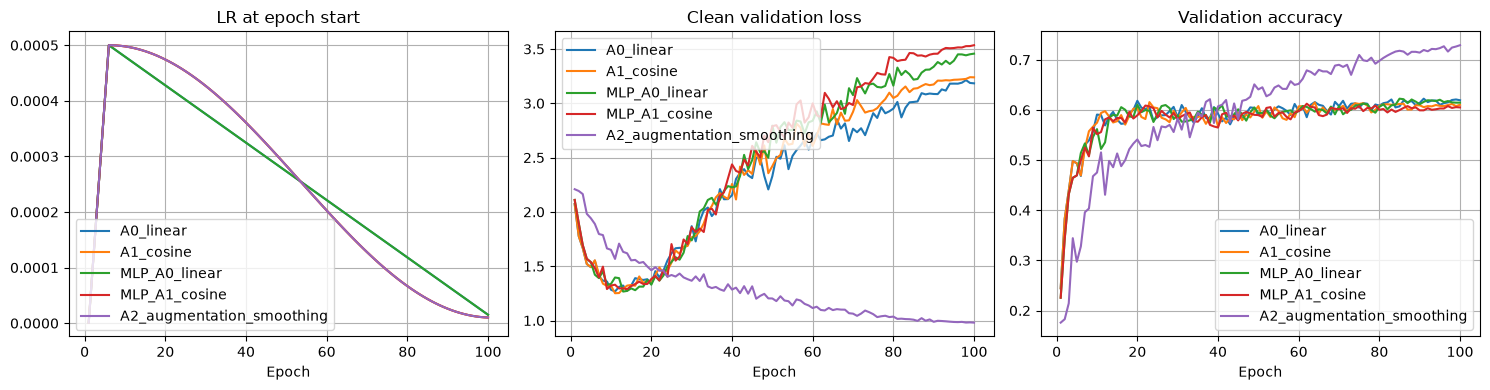

A0_linear selected epoch: 91 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6179896230864282, 'loss': 3.08482443971644, 'brier_score': 0.6828541312543809, 'ece': 0.3180005153544727, 'mean_confidence_incorrect': 0.8950377702713013}
A1_cosine selected epoch: 23 {'accuracy': 0.6156282998944034, 'macro_f1_score': 0.612395428063586, 'loss': 1.4334607119293374, 'brier_score': 0.5740851850564251, 'ece': 0.16159408488394467, 'mean_confidence_incorrect': 0.6749886870384216}
MLP_A0_linear selected epoch: 85 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6193434172041952, 'loss': 3.218034697938494, 'brier_score': 0.6707321918417717, 'ece': 0.3113274028428379, 'mean_confidence_incorrect': 0.8839903473854065}
MLP_A1_cosine selected epoch: 62 {'accuracy': 0.6124604012671595, 'macro_f1_score': 0.6081444226277524, 'loss': 2.872995398238443, 'brier_score': 0.6645175331721924, 'ece': 0.2967610700644057, 'mean_confidence_incorrect': 0.8410415053367615}
A2_augmentation_smoothing selected epoch: 

In [10]:
compare_completed_runs()


## Evaluate existing checkpoints without training

Run the imports/setup cell, then this cell; skip all training cells. Fill `saved_runs` with any completed run directories and the matching model builders, including A2 or the two-head distillation models when available. Each directory must contain `best.pth`, and its parent must contain the saved `split_indices.npz` and `dataset_manifest.json`. This restores the checkpoint's model dimensions and original validation membership. The saved image order and class mapping are checked against the clean dataset.

This only evaluates the saved weights. It writes a separate `evaluation_diagnostics.json` beside each checkpoint, preserving the earlier summary and checkpoint. Summary numbers alone cannot supply these new probability metrics. The same additions are enabled automatically for future calls to `run_experiment`. Distilled checkpoints use the two-head builder and probability fusion; evaluating them does not require the teacher.


In [11]:
saved_runs = {
    # "single_linear": (Path("artifacts/part2/SESSION/A0_linear"), build_vision_transformer_single_classifier),
    # "single_cosine": (Path("artifacts/part2/SESSION/A1_cosine"), build_vision_transformer_single_classifier),
    # "mlp_linear": (Path("artifacts/part2/SESSION/MLP_A0_linear"), build_vision_transformer),
    # "mlp_cosine": (Path("artifacts/part2/SESSION/MLP_A1_cosine"), build_vision_transformer),
    # "augmented_smoothed": (Path("artifacts/part2/SESSION/A2_augmentation_smoothing"), build_vision_transformer_single_classifier),
    # "soft_distillation": (Path("artifacts/part2/SESSION/soft_distillation"), build_distilled_vision_transformer),
    # "hard_distillation": (Path("artifacts/part2/SESSION/hard_distillation"), build_distilled_vision_transformer),
}
checkpoint_metrics = {}
if saved_runs:
    evaluation_pool = download_imagenette_dataset(root_dir=str(DATA_ROOT), split="train", image_size=224)
    current_samples = [
        {"image": str(Path(path).relative_to(Path(evaluation_pool._image_root))), "label": int(label)}
        for path, label in evaluation_pool._samples
    ]
for name, (run_dir, model_builder) in saved_runs.items():
    run_dir = Path(run_dir)
    manifest = json.loads((run_dir.parent / "dataset_manifest.json").read_text())
    assert manifest["ordered_samples"] == current_samples, "Dataset image order or targets changed."
    assert manifest["class_to_idx"] == evaluation_pool.class_to_idx, "Class mapping changed."
    with np.load(run_dir.parent / "split_indices.npz") as split:
        saved_validation = Subset(evaluation_pool, split["validation"].tolist())
    saved_loader = DataLoader(saved_validation, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    checkpoint = run_dir / "best.pth"
    model_config = torch.load(checkpoint, map_location="cpu", weights_only=True)["model_config"]
    model = model_builder(**model_config)
    metrics = evaluate_model(model, saved_loader, device, checkpoint_path=checkpoint, diagnostics=True)
    checkpoint_metrics[name] = metrics
    save_json(run_dir / "evaluation_diagnostics.json", metrics)
    print(name, {key: metrics[key] for key in
                 ("accuracy", "macro_f1_score", "loss", "brier_score", "ece", "mean_confidence_incorrect")})
    model.cpu()
if not saved_runs:
    print("Add the saved run directories above to evaluate checkpoints without training.")


Add the saved run directories above to evaluate checkpoints without training.


## C0/C1 — one frozen teacher for soft and hard distillation

Load the existing half-width ResNet-18 checkpoint below; this notebook does not retrain or replace it. Keep the teacher frozen and in evaluation mode, including its BatchNorm statistics. Its input convention remains [0,1], matching A2's unnormalized tensors. Both students start independently from scratch and use A2's exact image/batch transforms, scheduler, and budget.

The teacher checkpoint is a required local file. Its path and SHA-256 fingerprint identify the loaded weights. By default, `TEACHER_DATA_DIR` points to the original Part 1 session folder above `comparison/`; change that folder only if the teacher's original `dataset_manifest.json` and `split_indices.npz` were saved elsewhere. Matching metadata confirms the recorded class mapping, ordered relative paths/labels, and train/validation memberships agree with this session. It does not reconstruct missing training provenance. Mismatches stop execution; missing metadata is printed and recorded as unverified.

C0 uses soft targets and C1 hard argmax targets, with alpha 0.5 and temperature 1.0 retained from your configuration. The loss configuration records the exact soft-KL normalization. Dataset-target smoothing is applied once by A2's batch transform; it is not applied to the teacher's targets. Validation uses only clean labels and the student's fused probabilities, never the teacher-based training objective.


In [12]:
from models.resnet18 import ResNet18
from pipeline.checkpoints import load_checkpoint

TEACHER_CHECKPOINT = Path("artifacts/part1/20261112_034123_UTC/comparison/resnet18_half_width.pth")
TEACHER_DATA_DIR = TEACHER_CHECKPOINT.parent.parent


def verify_teacher_data(metadata_dir):
    manifest_path = metadata_dir / "dataset_manifest.json"
    split_path = metadata_dir / "split_indices.npz"
    missing = [str(path) for path in (manifest_path, split_path) if not path.is_file()]
    if missing:
        print("Teacher data provenance is UNVERIFIED; missing original metadata:", missing)
        return dict(status="unverified_missing_metadata", metadata_directory=str(metadata_dir), missing=missing)
    teacher_manifest = json.loads(manifest_path.read_text())
    current_manifest = json.loads((RESULTS_DIR / "dataset_manifest.json").read_text())
    for field in ("class_to_idx", "ordered_samples"):
        if teacher_manifest[field] != current_manifest[field]:
            raise ValueError(f"Teacher dataset mismatch: {field}")
    with np.load(split_path) as teacher_split:
        for field, current_indices in (("train", train_indices), ("validation", validation_indices)):
            if not np.array_equal(np.sort(teacher_split[field]), np.sort(current_indices)):
                raise ValueError(f"Teacher dataset mismatch: {field} membership")
    print("Teacher's saved dataset and split metadata match this session.")
    return dict(status="metadata_matches_current_split", metadata_directory=str(metadata_dir),
                checked=["class_to_idx", "ordered_samples", "train", "validation"])


if not TEACHER_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Required existing teacher checkpoint not found: {TEACHER_CHECKPOINT}")
teacher_data_verification = verify_teacher_data(TEACHER_DATA_DIR)
with TEACHER_CHECKPOINT.open("rb") as stream:
    teacher_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
teacher = ResNet18(num_classes=10, base_channels=32)
teacher_checkpoint_metadata = load_checkpoint(teacher, TEACHER_CHECKPOINT, device)
teacher.requires_grad_(False)
teacher.eval()
teacher_info = dict(
    checkpoint=str(TEACHER_CHECKPOINT), sha256=teacher_sha256,
    model="ResNet18", num_classes=10, base_channels=32,
    selected_epoch=teacher_checkpoint_metadata.get("epoch"),
    data_verification=teacher_data_verification,
    validation_metrics=str(RESULTS_DIR / "teacher" / "validation_metrics.json"),
)
save_json(RESULTS_DIR / "teacher" / "identity.json", teacher_info)


Teacher data provenance is UNVERIFIED; missing original metadata: ['artifacts/part1/20261112_034123_UTC/dataset_manifest.json', 'artifacts/part1/20261112_034123_UTC/split_indices.npz']


In [13]:
teacher_metrics = evaluate_model(
    teacher, validation_loader, device,
    diagnostics=True,
)
save_json(RESULTS_DIR / "teacher" / "validation_metrics.json", teacher_metrics)
print("Frozen teacher validation:", {name: teacher_metrics[name] for name in
                                     ("accuracy", "loss", "macro_f1_score", "ece")})


Frozen teacher validation: {'accuracy': 0.8141499472016895, 'loss': 0.8343186681852169, 'macro_f1_score': 0.8101129763924731, 'ece': 0.1036472759409213}


### C0 — soft distillation


In [14]:
from pipeline.losses import DistillationLoss

soft_loss = DistillationLoss(
    teacher, mode="soft", alpha=0.1, temperature=1.0,
)

c0_history, c0_summary = run_experiment(
    "soft_distillation",
    build_distilled_vision_transformer,
    scheduler="cosine_decay",
    train_dataset=augmented_train_data,
    batch_transform=batch_transform,
    criterion=soft_loss,
    teacher_info=teacher_info,
)


Epoch 1/100: train loss=2.1020, val loss=2.2367, val accuracy=0.1653, lr_start=1e-06, train=22.09s, val=3.33s
Epoch 2/100: train loss=2.0709, val loss=2.1703, val accuracy=0.2302, lr_start=0.0001, train=23.93s, val=3.24s
Epoch 3/100: train loss=2.0237, val loss=2.1050, val accuracy=0.2872, lr_start=0.0002, train=22.80s, val=3.32s
Epoch 4/100: train loss=1.9889, val loss=2.0111, val accuracy=0.3200, lr_start=0.0003, train=24.04s, val=2.74s
Epoch 5/100: train loss=1.9749, val loss=1.9777, val accuracy=0.3010, lr_start=0.0004, train=22.09s, val=2.69s
Epoch 6/100: train loss=1.9410, val loss=1.9179, val accuracy=0.3252, lr_start=0.0005, train=23.24s, val=3.22s
Epoch 7/100: train loss=1.9421, val loss=1.8179, val accuracy=0.4055, lr_start=0.0005, train=24.60s, val=2.74s
Epoch 8/100: train loss=1.9140, val loss=1.7975, val accuracy=0.3939, lr_start=0.0005, train=22.07s, val=2.67s
Epoch 9/100: train loss=1.9045, val loss=1.7588, val accuracy=0.4430, lr_start=0.0005, train=22.14s, val=2.69s
Ep

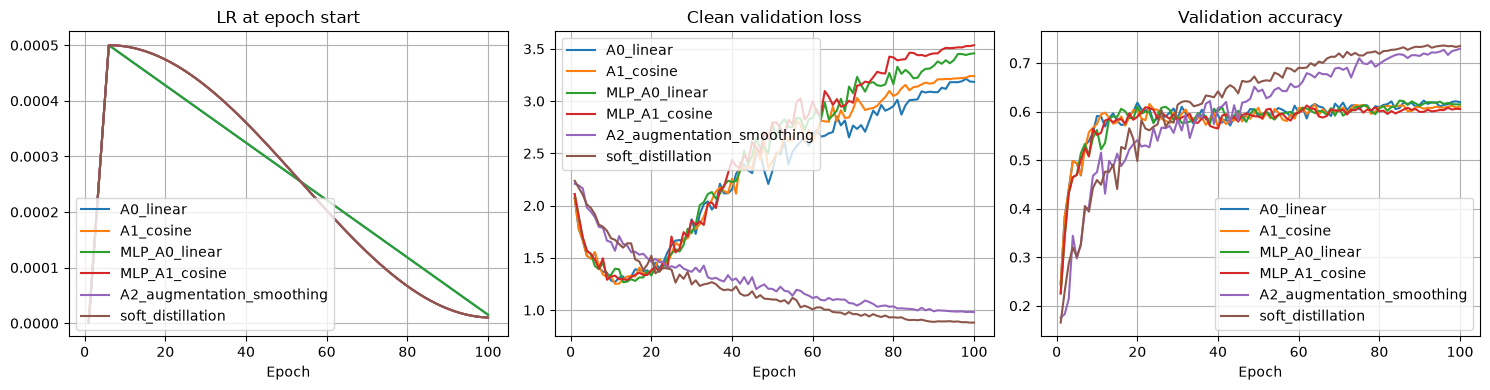

A0_linear selected epoch: 91 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6179896230864282, 'loss': 3.08482443971644, 'brier_score': 0.6828541312543809, 'ece': 0.3180005153544727, 'mean_confidence_incorrect': 0.8950377702713013}
A1_cosine selected epoch: 23 {'accuracy': 0.6156282998944034, 'macro_f1_score': 0.612395428063586, 'loss': 1.4334607119293374, 'brier_score': 0.5740851850564251, 'ece': 0.16159408488394467, 'mean_confidence_incorrect': 0.6749886870384216}
MLP_A0_linear selected epoch: 85 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6193434172041952, 'loss': 3.218034697938494, 'brier_score': 0.6707321918417717, 'ece': 0.3113274028428379, 'mean_confidence_incorrect': 0.8839903473854065}
MLP_A1_cosine selected epoch: 62 {'accuracy': 0.6124604012671595, 'macro_f1_score': 0.6081444226277524, 'loss': 2.872995398238443, 'brier_score': 0.6645175331721924, 'ece': 0.2967610700644057, 'mean_confidence_incorrect': 0.8410415053367615}
A2_augmentation_smoothing selected epoch: 

In [15]:
compare_completed_runs()


### C1 — hard distillation


In [16]:
hard_loss = DistillationLoss(
    teacher, mode="hard", alpha=0.5, temperature=1.0,
)

c1_history, c1_summary = run_experiment(
    "hard_distillation",
    build_distilled_vision_transformer,
    scheduler="cosine_decay",
    train_dataset=augmented_train_data,
    batch_transform=batch_transform,
    criterion=hard_loss,
    teacher_info=teacher_info,
)

Epoch 1/100: train loss=2.2769, val loss=2.2078, val accuracy=0.1695, lr_start=1e-06, train=22.03s, val=2.66s
Epoch 2/100: train loss=2.2260, val loss=2.0992, val accuracy=0.2439, lr_start=0.0001, train=22.03s, val=2.66s
Epoch 3/100: train loss=2.1742, val loss=2.0730, val accuracy=0.2867, lr_start=0.0002, train=22.03s, val=2.69s
Epoch 4/100: train loss=2.1239, val loss=1.9131, val accuracy=0.3057, lr_start=0.0003, train=23.71s, val=3.28s
Epoch 5/100: train loss=2.0805, val loss=1.8944, val accuracy=0.3379, lr_start=0.0004, train=22.90s, val=2.68s
Epoch 6/100: train loss=2.0471, val loss=1.7801, val accuracy=0.3775, lr_start=0.0005, train=22.06s, val=2.65s
Epoch 7/100: train loss=2.0212, val loss=1.7119, val accuracy=0.4197, lr_start=0.0005, train=22.06s, val=2.67s
Epoch 8/100: train loss=1.9833, val loss=1.7147, val accuracy=0.4366, lr_start=0.0005, train=22.93s, val=2.67s
Epoch 9/100: train loss=1.9622, val loss=1.6016, val accuracy=0.4778, lr_start=0.0005, train=24.46s, val=2.66s
Ep

## Compare all completed runs, including distillation

Reuse the same histories and summaries; the teacher setup never resets them. This updates the comparison figure with every run executed in this kernel, including C0/C1. Compare distillation with A2 while acknowledging the extra token/head; compare C0/C1 with one another using the same frozen teacher and two-head architecture.


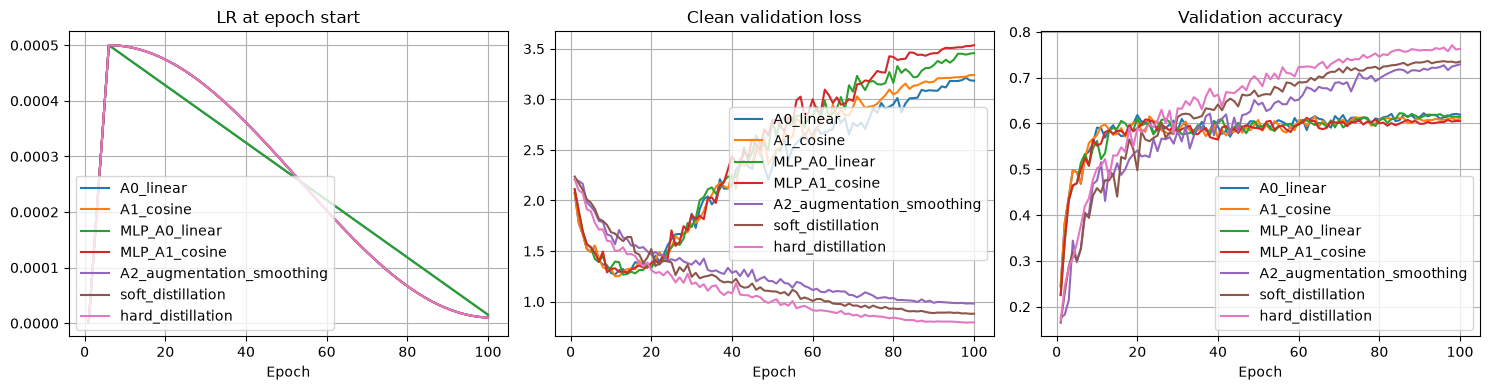

A0_linear selected epoch: 91 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6179896230864282, 'loss': 3.08482443971644, 'brier_score': 0.6828541312543809, 'ece': 0.3180005153544727, 'mean_confidence_incorrect': 0.8950377702713013}
A1_cosine selected epoch: 23 {'accuracy': 0.6156282998944034, 'macro_f1_score': 0.612395428063586, 'loss': 1.4334607119293374, 'brier_score': 0.5740851850564251, 'ece': 0.16159408488394467, 'mean_confidence_incorrect': 0.6749886870384216}
MLP_A0_linear selected epoch: 85 {'accuracy': 0.622492080253432, 'macro_f1_score': 0.6193434172041952, 'loss': 3.218034697938494, 'brier_score': 0.6707321918417717, 'ece': 0.3113274028428379, 'mean_confidence_incorrect': 0.8839903473854065}
MLP_A1_cosine selected epoch: 62 {'accuracy': 0.6124604012671595, 'macro_f1_score': 0.6081444226277524, 'loss': 2.872995398238443, 'brier_score': 0.6645175331721924, 'ece': 0.2967610700644057, 'mean_confidence_incorrect': 0.8410415053367615}
A2_augmentation_smoothing selected epoch: 

In [17]:
compare_completed_runs()
